# Supplemental Figure 2, Panel D

Scatter plot of feature importance from random forest (mean decrease in impurity) and ridge regression (absolute value, regression coefficient) for model trained on all ATAC-seq peaks

*Output: PanelD.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(patchwork)
library(RColorBrewer)
library(gridExtra)
library(here)
here::i_am("figures/SuppFig2/PanelD/PanelD.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()
#setwd("~/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig3/")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelD

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         gridExtra_2.3      RColorBrewer_1.1-3 patchwork_1.3.0   
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [3]:
#ML feature importance metrics - model trained on all ATAC-seq peaks, using BAF-dependence from 10uM/6h treatment
dat_10uM <- 
    read.delim(
        here("inputs", "ReModEx", "GM12878", "all_cRE", "dose_10uM", "feature_importance.csv"), 
        sep=',') %>% 
        arrange(feature)

# Statistics

In [4]:
#correlation between MDI importance and ridge regression coefficient 
p <- cor.test(log10(abs(dat_10uM$Ridge_coef)+1e-4), log10(dat_10uM$MDI_importance+1e-4),use="complete.obs")$p.value
r <- cor.test(log10(abs(dat_10uM$Ridge_coef)+1e-4), log10(dat_10uM$MDI_importance+1e-4),use="complete.obs")$estimate

# Generate plot

`geom_smooth()` using formula = 'y ~ x'
Saving 7 x 7 in image
`geom_smooth()` using formula = 'y ~ x'


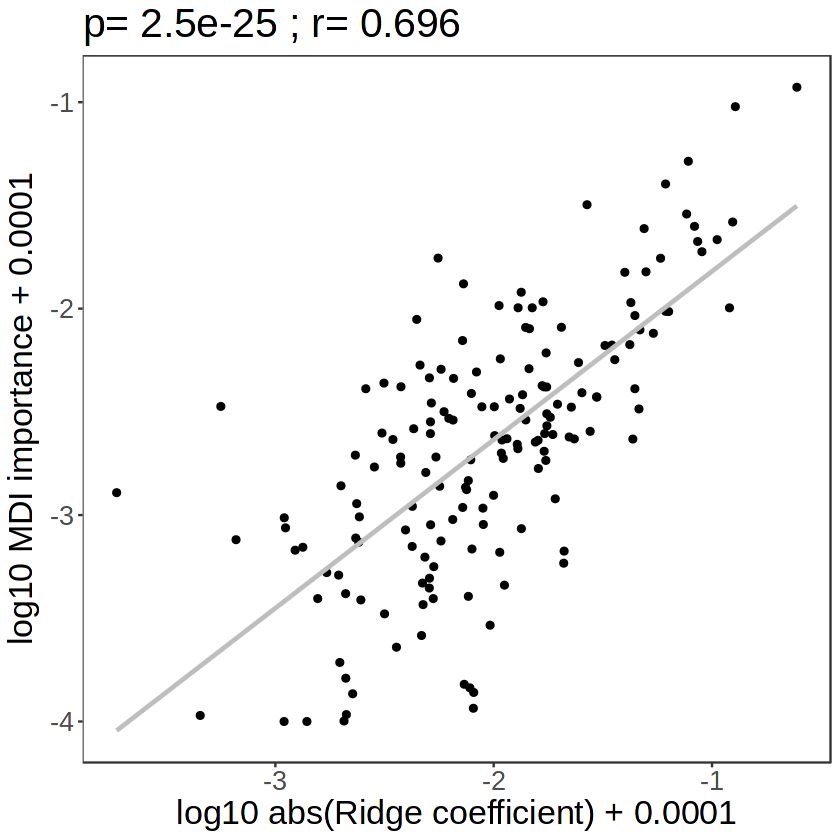

In [4]:

dat_10uM %>% 
    ggplot(aes(x=log10(abs(Ridge_coef)+1e-4), y=log10(MDI_importance+1e-4))) + 
    geom_point() + geom_smooth(method=lm, se=F, color="grey") + 
    theme(text=element_text(size=20)) + 
    xlab("log10 abs(Ridge coefficient) + 0.0001") + 
    ylab("log10 MDI importance + 0.0001") + 
    ggtitle(paste("p=",format(p,digits=3), ";", "r=", format(r,digits=3)))
ggsave("PanelD.pdf")
